#**Library**

In [ ]:
!pip install chromadb google-generativeai joblib scikit-learn pandas numpy

In [ ]:
!pip install gradio chromadb google-generativeai scikit-learn pandas numpy joblib

In [ ]:
!pip install protobuf>=4.25.8

In [ ]:
import pandas as pd
import numpy as np
import re
import os
import joblib
import chromadb
import google.genai as genai
import google.generativeai as genai
import gradio as gr
import pickle
import time
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from chromadb.utils import embedding_functions
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC

# **Data Preprocessing**

In [ ]:
# 1. Membaca Dataset dari File CSV yang Telah Diupload
file_1 = "gymnasyum_schedule inquiry & confirmation.csv"
file_2 = "gymnasyum_reschedule & cancellation.csv"

try:
    df_inquiry_conf = pd.read_csv(file_1)
    df_resched_cancel = pd.read_csv(file_2)

    # 2. Menggabungkan (Concat) Kedua Dataset
    df_combined = pd.concat([df_inquiry_conf, df_resched_cancel], ignore_index=True)

    # Mengacak (shuffle) urutan baris agar intent tidak mengelompok
    df = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

    print(f"✅ Berhasil menggabungkan data! Total dataset: {len(df)} baris.")

except FileNotFoundError:
    print("❌ ERROR: File CSV tidak ditemukan. Pastikan kamu sudah meng-upload kedua file ke panel sebelah kiri Colab dengan nama yang tepat.")
    # Agar kode di bawahnya tidak error jika file belum diupload
    df = pd.DataFrame({'text': [], 'intent': [], 'language_style': []})

# 3. Preprocessing Text
def preprocess_text(text):
    if not isinstance(text, str): # Menghindari error jika ada data kosong (NaN)
        return ""
    text = text.lower() # Ubah ke huruf kecil
    text = re.sub(r'[^a-z\s]', '', text) # Hapus tanda baca dan angka
    return text.strip()

# Terapkan fungsi preprocessing ke kolom 'text' dan simpan di kolom baru 'cleaned_text'
if not df.empty:
    df['cleaned_text'] = df['text'].apply(preprocess_text)

    print("✅ Preprocessing selesai. Berikut 5 baris pertama dari dataset gabungan:")
    display(df.head())

    # Melihat distribusi jumlah data per Intent
    print("\n📊 Distribusi Jumlah Data per Intent:")
    print(df['intent'].value_counts())

✅ Berhasil menggabungkan data! Total dataset: 6000 baris.
✅ Preprocessing selesai. Berikut 5 baris pertama dari dataset gabungan:


,text,intent,language_style,cleaned_text
0,Jadwal minggu ini minta tolong di share ya.,schedule_inquiry,tanpa_spesifik_jadwal,jadwal minggu ini minta tolong di share ya
1,Sesi latihan saya buat lusa mau di-reschedule ...,reschedule,tanpa_jadwal_baru,sesi latihan saya buat lusa mau direschedule d...
2,"Pagi admin, Saya bersedia hadir untuk kelas bo...",confirmation,formal,pagi admin saya bersedia hadir untuk kelas bod...
3,"Kak, Dengan ini saya nyatakan hadir untuk jadw...",confirmation,formal,kak dengan ini saya nyatakan hadir untuk jadwa...
4,Mohon hapus nama saya dari daftar hadir kelas ...,cancel,formal,mohon hapus nama saya dari daftar hadir kelas ...



📊 Distribusi Jumlah Data per Intent:
intent
schedule_inquiry    1500
reschedule          1500
confirmation        1500
cancel              1500
Name: count, dtype: int64


#**Build AI Model**

In [ ]:
# 1. Train-Test Split (Menggunakan Stratify agar proporsi data seimbang)
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned_text'],
    df['intent'],
    test_size=0.2,
    random_state=42,
    stratify=df['intent']
)

# 2. Ekstraksi Fitur (TF-IDF dengan N-Grams)
# ngram_range=(1,2) membuat model membaca kombinasi 2 kata (frasa)
# bukan sekadar 1 kata tunggal, sehingga lebih paham konteks chat
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_train_vec = tfidf_vectorizer.fit_transform(X_train)
X_test_vec = tfidf_vectorizer.transform(X_test)

# 3. Support Vector Machine (SVM) + Hyperparameter Tuning
print("🔍 Memulai proses Hyperparameter Tuning dengan 5-Fold Cross Validation...")

# Menyuruh model mencari parameter terbaik otomatis
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

# Inisialisasi model Support Vector Classifier (klasifikasi teks)
svm_model = SVC(random_state=42, probability=True)

# GridSearchCV akan membagi data 5 kali (cv=5) untuk menguji keandalan model
grid_search = GridSearchCV(svm_model, param_grid, cv=5, verbose=1, n_jobs=-1)
grid_search.fit(X_train_vec, y_train)

print(f"\n✅ Pencarian Selesai! Parameter Terbaik Ditemukan: {grid_search.best_params_}")
best_intent_classifier = grid_search.best_estimator_

# 4. Evaluasi Model pada Data Uji
y_pred = best_intent_classifier.predict(X_test_vec)
print("\n📊 Laporan Evaluasi Klasifikasi (SVM Pro - GridSearchCV):\n")
print(classification_report(y_test, y_pred, zero_division=0))

# 5. Menyimpan Model ke File
model_dir = "models"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

vectorizer_path = os.path.join(model_dir, 'tfidf_vectorizer.joblib')
model_path = os.path.join(model_dir, 'intent_classification_svm_model.joblib')

joblib.dump(tfidf_vectorizer, vectorizer_path)
joblib.dump(best_intent_classifier, model_path)

print(f"\n✅ Vectorizer (N-Gram) disimpan di: {vectorizer_path}")
print(f"✅ Model (SVM Terbaik) disimpan di: {model_path}")

🔍 Memulai proses Hyperparameter Tuning dengan 5-Fold Cross Validation...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

✅ Pencarian Selesai! Parameter Terbaik Ditemukan: {'C': 1, 'kernel': 'linear'}

📊 Laporan Evaluasi Klasifikasi (SVM Pro - GridSearchCV):

                  precision    recall  f1-score   support

          cancel       1.00      1.00      1.00        40
    confirmation       1.00      1.00      1.00       300
      reschedule       1.00      1.00      1.00        40
schedule_inquiry       1.00      1.00      1.00       300

        accuracy                           1.00       680
       macro avg       1.00      1.00      1.00       680
    weighted avg       1.00      1.00      1.00       680


✅ Vectorizer (N-Gram) disimpan di: models/tfidf_vectorizer.joblib
✅ Model (SVM Terbaik) disimpan di: models/intent_classification_svm_model.joblib


# Learning Curve Graph

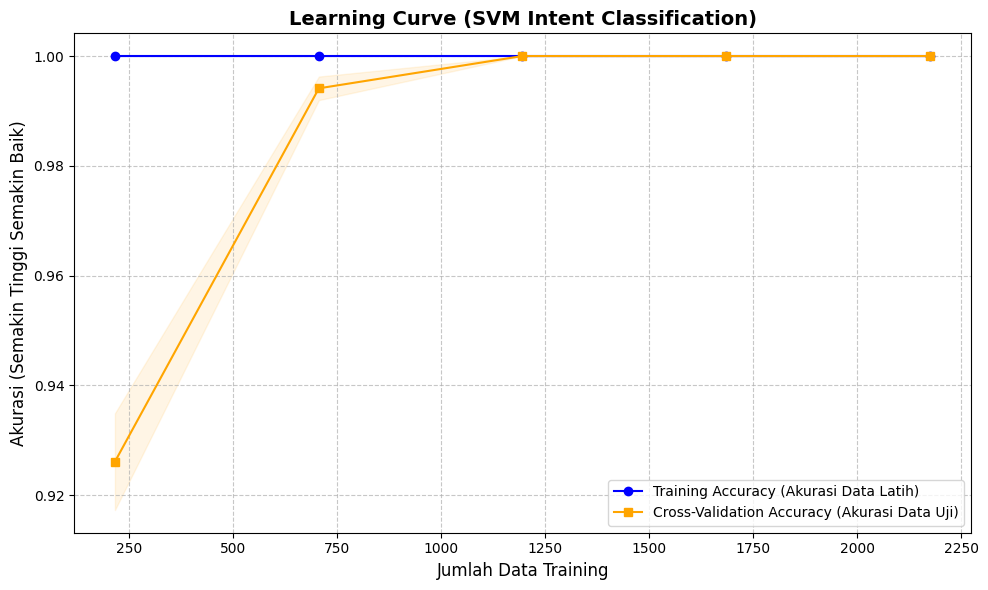

In [ ]:
def plot_learning_curve(estimator, X, y, title="Learning Curve (SVM Intent Classification)"):

    # Menghitung skor training dan validasi dengan 5-Fold Cross Validation
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y,
        cv=5,
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 5), # Membagi porsi data jadi 5 titik (10% s.d 100%)
        scoring='accuracy'
    )

    # Menghitung nilai rata-rata dan standar deviasi
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    # Pengaturan Grafik
    plt.figure(figsize=(10, 6))
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Jumlah Data Training", fontsize=12)
    plt.ylabel("Akurasi (Semakin Tinggi Semakin Baik)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)

    # Menggambar area Standar Deviasi
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="blue")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="orange")

    # Menggambar Garis Utama
    plt.plot(train_sizes, train_scores_mean, 'o-', color="blue",
             label="Training Accuracy (Akurasi Data Latih)")
    plt.plot(train_sizes, test_scores_mean, 's-', color="orange",
             label="Cross-Validation Accuracy (Akurasi Data Uji)")

    plt.legend(loc="lower right", fontsize=10)
    plt.tight_layout()
    plt.show()

# Pastikan variabel best_intent_classifier dan X_train_vec dari proses sebelumnya masih ada di memori Colab
plot_learning_curve(best_intent_classifier, X_train_vec, y_train)

# **Vector Database (ChromaDB: Model Embedding)**

In [ ]:
# 1. Penyimpanan Permanen (Persistent Storage)
# Data tidak akan hilang meski Colab di-restart
db_path = "./gym_vector_db"
chroma_client = chromadb.PersistentClient(path=db_path)
collection_name = "gym_knowledge_base"

# 2. Upgrade Embedding Model (Paham Bahasa Indonesia)
# Menggunakan model HuggingFace Multilingual agar akurasi pencarian teks Indonesia lebih tajam
indo_embedding = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name="paraphrase-multilingual-MiniLM-L12-v2"
)

try:
    chroma_client.delete_collection(name=collection_name)
except Exception:
    pass

# Memasukkan model embedding khusus ke dalam collection
collection = chroma_client.create_collection(
    name=collection_name,
    embedding_function=indo_embedding
)

# 3. Menyiapkan Dokumen (RAG)
gym_rules_docs = [
    "Kebijakan Reschedule: Reschedule jadwal hanya bisa dilakukan maksimal H-1 sebelum kelas dimulai.",
    "Target Member: Gymnasyum adalah gym eksklusif. Fasilitas sangat bersih, ramah lansia, aman dan nyaman.",
    "Harga dan Paket: Harga member bulanan adalah Rp 500.000, sudah termasuk kelas Zumba, Yoga, dan akses alat gym.",
    "Fasilitas: Kami menyediakan loker VIP, handuk bersih yang higienis, instruktur bersertifikat, sauna, ice bath, dan area relaksasi yang dilengkapi dengan teh herbal.",
    "Jam Operasional: Buka setiap hari dari jam 06:00 WIB sampai 23:00 WIB. Hari libur nasional tetap buka.",
    "Pembatalan (Cancel): Jika membatalkan kelas pada hari H, kuota kelas akan tetap hangus dan tidak ada pengembalian dana."
]

doc_ids = [f"doc_{i}" for i in range(len(gym_rules_docs))]

# Menambahkan data untuk filtering
doc_metadatas = [
    {"kategori": "aturan_jadwal"},
    {"kategori": "profil_gym"},
    {"kategori": "harga_paket"},
    {"kategori": "fasilitas"},
    {"kategori": "operasional"},
    {"kategori": "aturan_jadwal"}
]

# 4. Memasukkan informasi ke Vector Database
collection.add(
    documents=gym_rules_docs,
    ids=doc_ids,
    metadatas=doc_metadatas
)

print(f"✅ Sistem RAG Pro: Database berhasil dibuat di path '{db_path}'.")
print("✅ Embedding Model: paraphrase-multilingual-MiniLM-L12-v2 (Optimized for Indonesian).")

✅ Sistem RAG Pro: Database berhasil dibuat di path './gym_vector_db'.
✅ Embedding Model: paraphrase-multilingual-MiniLM-L12-v2 (Optimized for Indonesian).


# **Generatif AI with API model proprietary: Gemini**

In [ ]:
# 1. Mengambil API Key
try:
    from google.colab import userdata
    API_KEY = userdata.get('GEMINI_API_KEY')
except ImportError:
    # Untuk VS Code / environment lokal
    API_KEY = os.getenv("GEMINI_API_KEY")

if not API_KEY:
    raise ValueError("❌ API Key tidak ditemukan.")

# 2. Konfigurasi Client Generative AI
genai.configure(api_key=API_KEY)

# 3. Pengecekan Model dengan Error Handling
print("🔍 Mencari daftar model yang diizinkan untuk API Key ini...")
try:
    ada_model = False
    for m in genai.list_models():
        if 'generateContent' in m.supported_generation_methods:
            print(f"✅ Model tersedia: {m.name}")
            ada_model = True

    if not ada_model:
        print("⚠️ API Key valid, tapi tidak memiliki akses ke model teks (generateContent) apa pun.")
except Exception as e:
    print(f"❌ Error koneksi / API Key tidak valid. Detail: {e}")

🔍 Mencari daftar model yang diizinkan untuk API Key ini...
✅ Model tersedia: models/gemini-2.5-flash
✅ Model tersedia: models/gemini-2.5-pro
✅ Model tersedia: models/gemini-2.5-flash-preview-tts
✅ Model tersedia: models/gemini-2.5-pro-preview-tts
✅ Model tersedia: models/gemma-4-26b-a4b-it
✅ Model tersedia: models/gemma-4-31b-it
✅ Model tersedia: models/gemini-flash-latest
✅ Model tersedia: models/gemini-flash-lite-latest
✅ Model tersedia: models/gemini-pro-latest
✅ Model tersedia: models/gemini-2.5-flash-lite
✅ Model tersedia: models/gemini-2.5-flash-image
✅ Model tersedia: models/gemini-3-flash-preview
✅ Model tersedia: models/gemini-3.1-pro-preview
✅ Model tersedia: models/gemini-3.1-pro-preview-customtools
✅ Model tersedia: models/gemini-3.1-flash-lite-preview
✅ Model tersedia: models/gemini-3.1-flash-lite
✅ Model tersedia: models/gemini-3-pro-image-preview
✅ Model tersedia: models/gemini-3-pro-image
✅ Model tersedia: models/nano-banana-pro-preview
✅ Model tersedia: models/gemini-3

In [ ]:
# 1. Konfigurasi API
try:
    from google.colab import userdata
    API_KEY = userdata.get('GEMINI_API_KEY')
    genai.configure(api_key=API_KEY)
except Exception as e:
    print("⚠️ API Key belum dikonfigurasi.")

# 2. Inisialisasi Model LLM
llm_model = genai.GenerativeModel('gemini-3.8-flash')
print("✅ Model LLM (Gemini) berhasil diinisialisasi.")

# 3. Memuat Model Machine Learning dengan Error Handling
print("⏳ Memuat model Machine Learning (N-Gram & SVM)...")
try:
    # Memuat vectorizer dan model yang sudah di-upgrade sebelumnya
    loaded_vectorizer = joblib.load('models/tfidf_vectorizer.joblib')
    loaded_classifier = joblib.load('models/intent_classification_svm_model.joblib')

    print("✅ Model Machine Learning berhasil dimuat dan siap digunakan.")
except FileNotFoundError as e:
    print(f"❌ CRITICAL ERROR: File model tidak ditemukan. Pastikan kamu sudah menjalankan proses Training SVM sebelumnya. Detail: {e}")
except Exception as e:
    print(f"❌ ERROR: Gagal memuat model. Detail: {e}")

✅ Model LLM (Gemini) berhasil diinisialisasi.
⏳ Memuat model Machine Learning (N-Gram & SVM)...
✅ Model Machine Learning berhasil dimuat dan siap digunakan.


# Multi-bubble Chat Buffer Simulator

In [ ]:
# Dictionary untuk menyimpan riwayat chat dan waktu aktivitas terakhir
# Format: { 'sender_id': {'messages': [...], 'last_activity': timestamp} }
chat_buffers = {}

def handle_multi_bubble_messages(sender_id, new_message):
    """
    Menyimpan bubble chat yang masuk dan memperbarui waktu (timestamp) aktivitas terakhir.
    """
    current_time = time.time()

    # Jika ini pesan pertama dari user, inisialisasi buffer-nya
    if sender_id not in chat_buffers:
        chat_buffers[sender_id] = {
            'messages': [],
            'last_activity': current_time
        }

    # Tambahkan pesan ke buffer dan update waktu terakhir dia mengetik
    chat_buffers[sender_id]['messages'].append(new_message.strip())
    chat_buffers[sender_id]['last_activity'] = current_time

    # Tampilkan status sementara (untuk simulasi)
    return " ".join(chat_buffers[sender_id]['messages'])

def is_user_done_typing(sender_id, delay_seconds=5):
    """
    Fungsi krusial Backend: Mengecek apakah user sudah berhenti mengetik
    berdasarkan jeda waktu (delay) sejak pesan terakhir.
    """
    if sender_id not in chat_buffers:
        return False

    time_elapsed = time.time() - chat_buffers[sender_id]['last_activity']

    # Jika waktu yang berlalu sudah melebihi batas delay (misal 5 detik), berarti user selesai
    return time_elapsed >= delay_seconds

def process_and_clear_buffer(sender_id):
    """
    Mengambil pesan utuh untuk dilempar ke Machine Learning / AI,
    lalu membersihkan memori agar tidak terjadi Memory Leak.
    """
    if sender_id in chat_buffers:
        combined_message = " ".join(chat_buffers[sender_id]['messages'])
        del chat_buffers[sender_id] # Bersihkan memori
        return combined_message
    return None

# Pipeline Integration

In [ ]:
def process_customer_request(sender_id, incoming_bubble, available_slots_str, action="proses_ai"):
    # AKSI 1: Hanya menampung chat ke dalam Buffer (Simulasi user sedang mengetik)
    if action == "tambah_buffer":
        if not incoming_bubble.strip():
            return "Error: Pesan tidak boleh kosong.", "⏳", "⏳", "⏳"

        combined_message = handle_multi_bubble_messages(sender_id, incoming_bubble)
        return combined_message, "⏳ Menunggu user selesai...", "⏳ Menunggu...", "⏳ Menunggu..."

    # AKSI 2: Eksekusi AI (Simulasi jeda delay habis)
    elif action == "proses_ai":
        # Jaga-jaga jika ada teks yang lupa di-buffer, kita masukkan sekalian
        if incoming_bubble.strip():
            handle_multi_bubble_messages(sender_id, incoming_bubble)

        customer_message = process_and_clear_buffer(sender_id)
        if not customer_message:
            return "❌ Buffer kosong. Silakan kirim chat terlebih dahulu.", "-", "-", "-"

        # --- TAHAP 1: Klasifikasi Intent ---
        cleaned_message = preprocess_text(customer_message)
        message_vector = loaded_vectorizer.transform([cleaned_message])
        predicted_intent = loaded_classifier.predict(message_vector)[0]

        # --- TAHAP 2: Retrieval (RAG) ---
        retrieval_results = collection.query(query_texts=[cleaned_message], n_results=2)
        relevant_context = " | ".join(retrieval_results['documents'][0])

        # --- TAHAP 3: Generative AI Draft ---
        available_slots = [slot.strip() for slot in available_slots_str.split(",")] if available_slots_str.strip() else []
        slots_text = ", ".join(available_slots) if available_slots else "Tidak ada slot tersedia"

        prompt = f"""
        Kamu adalah asisten admin dan konsultan kebugaran yang sangat ramah, sabar, penuh empati, dan profesional di Gymnasyum.
        INFORMASI RELEVAN DARI DATABASE ATURAN GYM: {relevant_context}
        DATA PERMINTAAN SAAT INI:
        - Rangkaian pesan pelanggan (Multi-bubble): "{customer_message}"
        - Niat (Intent) sistem: {predicted_intent}
        - Slot jadwal alternatif yang tersedia: {slots_text}

        Tugas:
        1. Analisis apakah pelanggan menyebutkan keluhan kesehatan atau kondisi fisik.
        2. Buatlah SATU paragraf DRAFT balasan WhatsApp yang mengacu kuat pada aturan gym di atas.
        3. Jika ada keluhan sakit/pegal, berikan empati/doa, lalu rekomendasikan slot alternatif (jika ada).
        4. Gunakan bahasa Indonesia yang sangat sopan dan natural. Jangan beri placeholder.
        """

        try:
            response = llm_model.generate_content(prompt)
            generated_draft = response.text.strip()
        except Exception as e:
            generated_draft = f"Error Generative AI: {e}"

        return customer_message, predicted_intent, relevant_context, generated_draft

# **AI Chat Testing**

In [ ]:
test_sender_id = "test_customer_01"
# Kita pecah pesan menjadi 3 bubble seolah-olah user menekan 'Enter' berkali-kali
test_bubbles = [
    "Mbak,",
    "besok sore saya nggak bisa ikut kelas zumba ya",
    "karena badan pegal."
]
web_slots_str = "Sabtu 08:00 WIB (Kelas Zumba)"

print("⏳ Menjalankan pengujian program (Simulasi Multi-Bubble)...\n")

# 1. Simulasi Backend menerima chat satu per satu (Delay Buffer)
for i, bubble in enumerate(test_bubbles):
    print(f"📥 [Waktu: 00:0{i+1}] User mengetik: '{bubble}'")

    # Hanya untuk bubble terakhir, kita panggil fungsi utama agar dieksekusi.
    # Untuk bubble pertama dan kedua, kita simulasikan backend hanya menyimpannya di buffer.
    if i == len(test_bubbles) - 1:
        print("\n⏳ User berhenti mengetik. Backend memproses seluruh buffer ke AI...")
        customer_msg, pred_intent, retrieved_ctx, ai_response = process_customer_request(
            test_sender_id,
            bubble,
            web_slots_str
        )
    else:
        # Menyimpan ke memori sementara (fungsi yang sudah dibuat sebelumnya)
        handle_multi_bubble_messages(test_sender_id, bubble)
        time.sleep(1) # Simulasi jeda user sedang mengetik bubble selanjutnya

print("\n" + "="*60)
print("SMART RESCHEDULE ASSISTANT RESULT (RAG PIPELINE)")
print("="*60)
print(f"📦 COMBINED MESSAGE (BUFFER):\n{customer_msg}\n")
print(f"🤖 PREDICTED INTENT:\n{pred_intent}\n")
print(f"🔍 RETRIEVED CONTEXT (CHROMA DB):\n{retrieved_ctx}\n")
print(f"📝 AI DRAFT RESPONSE:\n{ai_response}")
print("="*60)

⏳ Menjalankan pengujian program (Simulasi Multi-Bubble)...

📥 [Waktu: 00:01] User mengetik: 'Mbak,'
📥 [Waktu: 00:02] User mengetik: 'besok sore saya nggak bisa ikut kelas zumba ya'
📥 [Waktu: 00:03] User mengetik: 'karena badan pegal.'

⏳ User berhenti mengetik. Backend memproses seluruh buffer ke AI...

SMART RESCHEDULE ASSISTANT RESULT (RAG PIPELINE)
📦 COMBINED MESSAGE (BUFFER):
Mbak, besok sore saya nggak bisa ikut kelas zumba ya karena badan pegal.

🤖 PREDICTED INTENT:
schedule_inquiry

🔍 RETRIEVED CONTEXT (CHROMA DB):
Pembatalan (Cancel): Jika membatalkan kelas pada hari H, kuota kelas akan tetap hangus dan tidak ada pengembalian dana. | Kebijakan Reschedule: Reschedule jadwal hanya bisa dilakukan maksimal H-1 sebelum kelas dimulai.

📝 AI DRAFT RESPONSE:
Error Generative AI: 504 Deadline Exceeded


# **Integration of the RAG system as an additional feature into the Gradio user interface (optional)**

In [ ]:
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🏋️‍♀️ Smart Reschedule Assistant (Gymnasyum)")
    gr.Markdown("Dilengkapi dengan penanganan **Multi-Bubble Chat Buffering** untuk simulasi chat WhatsApp nyata.")

    with gr.Row():
        with gr.Column():
            input_sender = gr.Textbox(
                label="ID Pengirim / No. WhatsApp (Contoh: 0812345)",
                value="customer_001"
            )
            input_message = gr.Textbox(
                label="Kirim Bubble Chat Masuk",
                placeholder="Ketik bubble chat satu persatu di sini (misal: 'Mbak...', lalu 'Besok jadwal pindah ya')"
            )
            input_slots = gr.Textbox(
                label="Slot Alternatif dari Web (Opsional)",
                placeholder="Contoh: Sabtu 08:00 WIB (Zumba)"
            )

            # FITUR BARU: Dua tombol berjajar
            with gr.Row():
                btn_buffer = gr.Button("💬 Kirim ke Buffer", variant="secondary")
                btn_proses = gr.Button("🚀 Proses AI (Selesai Mengetik)", variant="primary")

        with gr.Column():
            output_combined = gr.Textbox(label="📦 Hasil Gabungan Bubble Chat (Buffer)")
            output_intent = gr.Textbox(label="🤖 Prediksi Intent (Custom ML Model)")
            output_context = gr.Textbox(label="🔍 Konteks Relevan (ChromaDB RAG)")
            output_draft = gr.Textbox(label="📝 Draft Balasan Admin (Gemini AI)")

    # Logika eksekusi Tombol 1 (Hanya Buffer)
    btn_buffer.click(
        fn=lambda s, msg, slots: process_customer_request(s, msg, slots, action="tambah_buffer"),
        inputs=[input_sender, input_message, input_slots],
        outputs=[output_combined, output_intent, output_context, output_draft]
    )

    # Logika eksekusi Tombol 2 (Proses ML & AI)
    btn_proses.click(
        fn=lambda s, msg, slots: process_customer_request(s, msg, slots, action="proses_ai"),
        inputs=[input_sender, input_message, input_slots],
        outputs=[output_combined, output_intent, output_context, output_draft]
    )

demo.launch(inline=False, share=True)

/tmp/ipykernel_473/1098577925.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b8dd82ad05f4b49142.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
